# Crypto Clustering: Explore, Scale, Reduce and Explain

In Lab 04 you investigated data and practised scaling. Now use those skills to
group cryptocurrencies by their observed price-change patterns, then investigate
what changes when seven features are represented by three principal components.
Keep the original workflow: **EDA → scaling → K-Means → PCA → K-Means → comparison**.

## Working instructions
- Save your own copy of this notebook beside `crypto_market_data.csv`.
- Use pandas, matplotlib, hvplot, scikit-learn and a Jupyter environment.
- Write code in the exercise cells. Add short explanations in the Markdown answer cells;
  Write your explanations in English.
- The original workflow keeps its expected tables, arrays and charts, as in last
  year's notebook. These are reference outputs, not evidence that your blank work
  cells have run. The new EDA section contains guidance only, without prepared
  charts or results. Run your completed code to produce your own outputs.
- **Recommended EDA extension: about 6 additional plots beyond those already
  provided in this notebook.** Choose your own questions, chart types and features.
  This is a recommendation, not a strict minimum: fewer plots are acceptable if
  they cover your questions well and you explain your choice. Repetitive plots
  do not strengthen an investigation.
- For each EDA chart, state the question, explain why the chart fits it, and give
  one observation supported by a value, range or named coin. Two short sentences
  can be enough. End the EDA with **three main findings, one limitation, and one
  question to investigate during clustering**. Synthesize your evidence instead
  of repeating every chart caption.
- Seven checkpoints cover the full workflow. Four are self-checks or group
  discussion; three ask for 1–2 written sentences. Follow the response labels.
- Finish with one short critical LLM conversation about an existing finding from
  any stage, not just EDA. Reuse existing evidence; no new plot or report is needed.
- Before submission, restart the kernel, run all your completed cells in order,
  and save the notebook with its outputs and explanations. Submit the notebook
  unless your course publication instructions specify otherwise.

## Understand the data
Each row is one coin. `coin_id` identifies it; it is not a numerical feature.
The seven numerical columns are percentage price changes over 24 hours, 7, 14,
30, 60 and 200 days, and one year. Negative means a decrease; positive means an
increase. These are different time windows for the same coins, not a daily time
series. There is no target label and no investment prediction in this exercise.

In [ ]:
# Import required libraries and dependencies
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import hvplot.pandas
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


### Load and Inspect the Data
Load `crypto_market_data.csv` as `df_market_data`, using `coin_id` as the index.
Display sample rows, summary statistics, a first overview chart and the column
names in the cells below. The later workflow uses these exact variable names.
The overview chart is a starting example; use your own chart choices in the EDA.

In [43]:
# Load the data into a Pandas DataFrame
df_market_data = pd.read_csv("Data/crypto_market_data.csv",index_col='coin_id')
# Display sample data
display(df_market_data.head())

,price_change_percentage_24h,price_change_percentage_7d,price_change_percentage_14d,price_change_percentage_30d,price_change_percentage_60d,price_change_percentage_200d,price_change_percentage_1y
coin_id,,,,,,,
bitcoin,1.08388,7.60278,6.57509,7.67258,-3.25185,83.51840,37.51761
ethereum,0.22392,10.38134,4.80849,0.13169,-12.88890,186.77418,101.96023
tether,-0.21173,0.04935,0.00640,-0.04237,0.28037,-0.00542,0.01954
ripple,-0.37819,-0.60926,2.24984,0.23455,-17.55245,39.53888,-16.60193
bitcoin-cash,2.90585,17.09717,14.75334,15.74903,-13.71793,21.66042,14.49384


In [44]:
# Generate summary statistics
display(df_market_data.describe())

,price_change_percentage_24h,price_change_percentage_7d,price_change_percentage_14d,price_change_percentage_30d,price_change_percentage_60d,price_change_percentage_200d,price_change_percentage_1y
count,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000
mean,-0.269686,4.497147,0.185787,1.545693,-0.094119,236.537432,347.667956
std,2.694793,6.375218,8.376939,26.344218,47.365803,435.225304,1247.842884
min,-13.527860,-6.094560,-18.158900,-34.705480,-44.822480,-0.392100,-17.567530
25%,-0.608970,0.047260,-5.026620,-10.438470,-25.907990,21.660420,0.406170
50%,-0.063410,3.296410,0.109740,-0.042370,-7.544550,83.905200,69.691950
75%,0.612090,7.602780,5.510740,4.578130,0.657260,216.177610,168.372510
max,4.840330,20.694590,24.239190,140.795700,223.064370,2227.927820,7852.089700


In [77]:
# Plot your data to see what's in your DataFrame - using hvplot
df_market_data.hvplot()

:NdOverlay   [Variable]
   :Curve   [coin_id]   (value)

In [78]:
# list the columns in the DataFrame
print(f"Columns of the dataframe are:\n {df_market_data.columns}")

Columns of the dataframe are:
 Index(['price_change_percentage_24h', 'price_change_percentage_7d',
       'price_change_percentage_14d', 'price_change_percentage_30d',
       'price_change_percentage_60d', 'price_change_percentage_200d',
       'price_change_percentage_1y'],
      dtype='object')


### Your EDA: Choose Questions That Matter
Reuse the methods from Lab 04. Check shape, types, missing values and duplicates;
decide whether any preparation is needed and justify your decision. Do not
automatically remove an unusual coin just because its change is large.

Choose your own investigation. For example: How do spreads differ between time
windows? Are short- and long-window changes related? Which coins are unusual?
Use whichever plots answer your questions. A line connecting coin names is an
overview, not a chronological price trajectory.

There is no prescribed set of charts or a prepared EDA result to reproduce.
Your choice of questions and evidence is part of the task. Use one of your
existing findings for the closing LLM conversation; no extra chart is needed.

Add or duplicate code and Markdown cells as needed. Preserve the seven numerical
features for the common workflow below; discuss any alternative feature choice
as an optional extension. Keep `df_market_data` unchanged for interpretation.

In [ ]:

print("Shape:", df_market_data.shape)
print("\nData Types & Info:")
df_market_data.info()
print("\nMissing Values:")
print(df_market_data.isnull().sum())
print("\nDuplicate Rows:", df_market_data.duplicated().sum())
display(df_market_data.describe())

# Preparation Decision: Keep the dataset as is without dropping rows or changing values.
# Justification:
# 1. There are no missing values or duplicated values. 
# 2. Extreme values are fine

Shape: (41, 7)

Data Types & Info:
<class 'pandas.core.frame.DataFrame'>
Index: 41 entries, bitcoin to digibyte
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   price_change_percentage_24h   41 non-null     float64
 1   price_change_percentage_7d    41 non-null     float64
 2   price_change_percentage_14d   41 non-null     float64
 3   price_change_percentage_30d   41 non-null     float64
 4   price_change_percentage_60d   41 non-null     float64
 5   price_change_percentage_200d  41 non-null     float64
 6   price_change_percentage_1y    41 non-null     float64
dtypes: float64(7)
memory usage: 2.6+ KB

Missing Values:
price_change_percentage_24h     0
price_change_percentage_7d      0
price_change_percentage_14d     0
price_change_percentage_30d     0
price_change_percentage_60d     0
price_change_percentage_200d    0
price_change_percentage_1y      0
dtype: int64

Duplicate Rows:

,price_change_percentage_24h,price_change_percentage_7d,price_change_percentage_14d,price_change_percentage_30d,price_change_percentage_60d,price_change_percentage_200d,price_change_percentage_1y
count,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000,41.000000
mean,-0.269686,4.497147,0.185787,1.545693,-0.094119,236.537432,347.667956
std,2.694793,6.375218,8.376939,26.344218,47.365803,435.225304,1247.842884
min,-13.527860,-6.094560,-18.158900,-34.705480,-44.822480,-0.392100,-17.567530
25%,-0.608970,0.047260,-5.026620,-10.438470,-25.907990,21.660420,0.406170
50%,-0.063410,3.296410,0.109740,-0.042370,-7.544550,83.905200,69.691950
75%,0.612090,7.602780,5.510740,4.578130,0.657260,216.177610,168.372510
max,4.840330,20.694590,24.239190,140.795700,223.064370,2227.927820,7852.089700


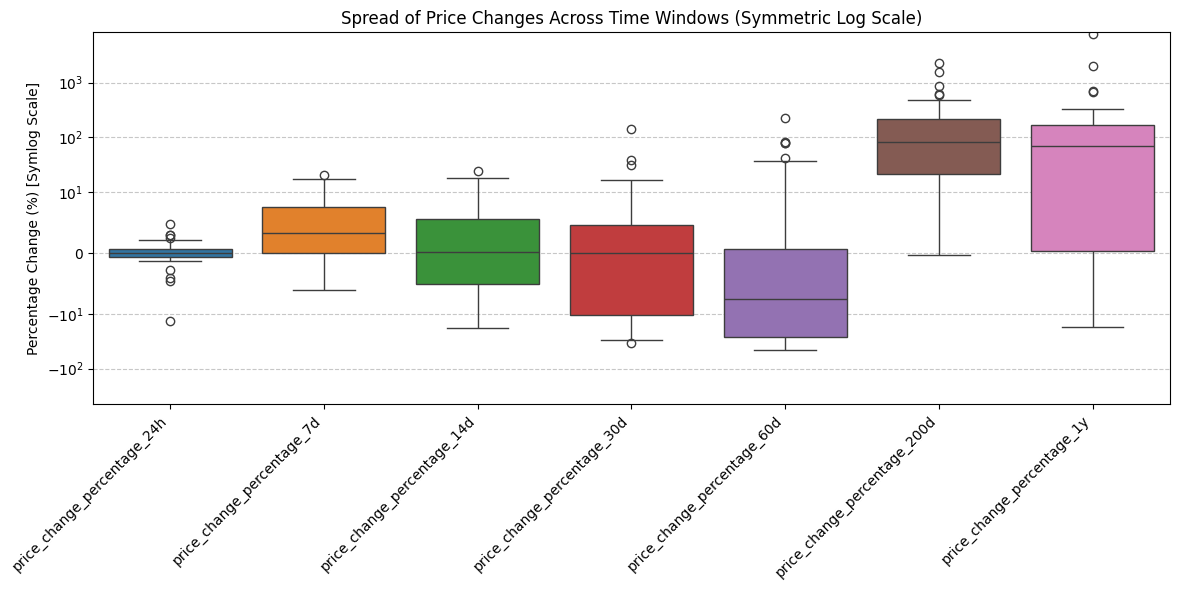

In [ ]:
# Question 1: How do distributions and spreads changes across time windows?
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_market_data)
plt.yscale('symlog', linthresh=10) # linear between -10% and +10%, logarithmic beyond
plt.xticks(rotation=45, ha='right')
plt.title("Spread of Price Changes Across Time Windows (Symmetric Log Scale)")
plt.ylabel("Percentage Change (%) [Symlog Scale]")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
# After examining the graph we decided to log scale the y axis of the boxplot and see it clearly

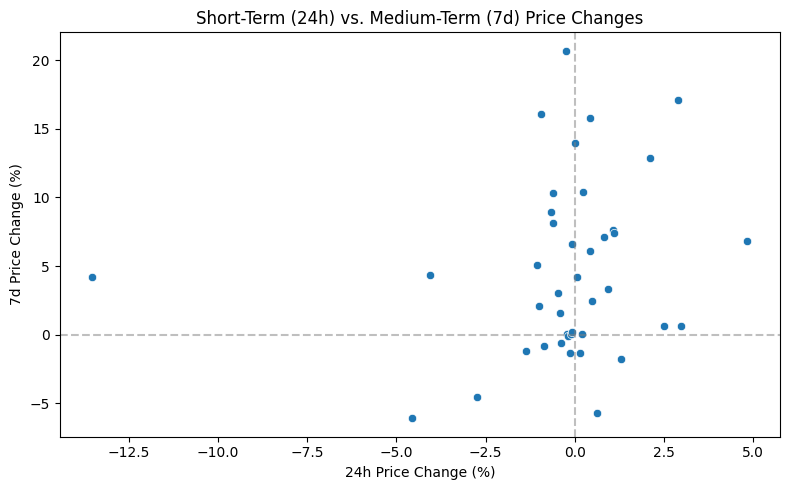

In [86]:
# Question 2: Are short-term (24h) and medium-term (7d) changes correlated?
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_market_data,
    x='price_change_percentage_24h',
    y='price_change_percentage_7d'
)
plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
plt.title("Short-Term (24h) vs. Medium-Term (7d) Price Changes")
plt.xlabel("24h Price Change (%)")
plt.ylabel("7d Price Change (%)")
plt.tight_layout()
plt.show()

In [ ]:
# Question 3: Which coins are major outliers 200d+?
# We need to identift coins in the 95th percentile or more extreme values for 200d and 1y changes
long_term_outliers = df_market_data[
    (df_market_data['price_change_percentage_200d'] > 100) |
    (df_market_data['price_change_percentage_1y'] > 100)
]
print("Coins with big long-term changes (>100%):")
display(long_term_outliers[['price_change_percentage_200d', 'price_change_percentage_1y']])

Coins with extreme long-term changes (>100%):


,price_change_percentage_200d,price_change_percentage_1y
coin_id,,
ethereum,186.77418,101.96023
binancecoin,155.61937,69.69195
chainlink,403.22917,325.13186
cardano,264.51418,156.09756
crypto-com-chain,226.70782,305.05908
monero,169.52147,141.04116
tron,132.88436,59.23821
tezos,43.42842,140.01279
okb,39.95853,141.95791


**Your explanation:**

_Write your brief answer here._

### Checkpoint 1 — Data and Your Investigation

What does one row represent, and are the seven time-window columns a daily time series? Name the question your chosen EDA evidence addresses.

*Self-check / group discussion: no separate written answer required.*

---

### Prepare the Data
K-Means uses distances between observations. Scale the seven numerical features
so that a feature with a larger spread does not dominate simply because of its
scale. Reuse what you learned in Lab 04; keep the coin names as the index.
Preserve `df_market_data` for interpretation in the original percentage units.
Store the scaled array as `market_scaled` and the corresponding DataFrame as
`market_scale_df`, preserving the original column names and coin index.

In [88]:
# Use the `StandardScaler()` module from scikit-learn to normalize the data from the CSV file
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
market_scaled = scaler.fit_transform(df_market_data)

# Review the first five rows of the scaled data
market_scaled[:5]

array([[ 0.50852937,  0.49319307,  0.77220043,  0.23545963, -0.0674951 ,
        -0.35595348, -0.25163688],
       [ 0.18544589,  0.93444504,  0.55869212, -0.05434093, -0.27348273,
        -0.11575947, -0.19935211],
       [ 0.02177396, -0.70633685, -0.02168042, -0.06103015,  0.00800452,
        -0.55024692, -0.28206051],
       [-0.04076438, -0.81092807,  0.24945797, -0.05038797, -0.37316402,
        -0.45825882, -0.29554614],
       [ 1.19303608,  2.00095907,  1.76061001,  0.54584206, -0.29120287,
        -0.49984776, -0.27031695]])

In [89]:
# Create a DataFrame with the scaled data
market_scale_df = pd.DataFrame(
    market_scaled, 
    columns=df_market_data.columns
)

# Copy the crypto names from the original DataFrame
market_scale_df['coin_id'] = df_market_data.index

# Set the coin_id column as index
market_scale_df = market_scale_df.set_index('coin_id')

# Display the scaled DataFrame
market_scale_df.head()


,price_change_percentage_24h,price_change_percentage_7d,price_change_percentage_14d,price_change_percentage_30d,price_change_percentage_60d,price_change_percentage_200d,price_change_percentage_1y
coin_id,,,,,,,
bitcoin,0.508529,0.493193,0.772200,0.235460,-0.067495,-0.355953,-0.251637
ethereum,0.185446,0.934445,0.558692,-0.054341,-0.273483,-0.115759,-0.199352
tether,0.021774,-0.706337,-0.021680,-0.061030,0.008005,-0.550247,-0.282061
ripple,-0.040764,-0.810928,0.249458,-0.050388,-0.373164,-0.458259,-0.295546
bitcoin-cash,1.193036,2.000959,1.760610,0.545842,-0.291203,-0.499848,-0.270317


### Checkpoint 2 — Scaling

Which columns entered scaling, and what changed? Why might features measured in the same percentage unit still need scaling?

*Self-check / group discussion: no separate written answer required.*

---

### Choose a Reasonable k Using the Scaled Features
K-Means assigns each coin to one of `k` groups. Its centres are calculated in
the feature space supplied to the model. Inertia summarizes squared distances
to the assigned centres; it usually decreases as more clusters are allowed.
Look for a bend in the Elbow curve where adding groups brings less reduction.
A bend supports a choice; it does not prove a unique correct number of groups.

Use `k_values = list(range(1, 12))`, collect `inertia`, and create `elbow_df`
with columns `k` and `inertia`. Store the chart as `elbow_plot`.
Keep `random_state=0` and `n_init=10` in every K-Means model for repeatability.

In [90]:
# Create a list with the number of k-values from 1 to 11
k_values = list(range(1, 12))

In [91]:
from sklearn.cluster import KMeans

# Create an empty list to store the inertia values
inertia = []

# Loop through the k-values
for k in k_values:
    # Create the KMeans model
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    
    # Fit the model to the data
    model.fit(market_scale_df)
    
    # Append the inertia to the inertia list
    inertia.append(model.inertia_)

In [92]:
# Create a dictionary with the data to plot the Elbow curve
elbow_data = {
    "k": k_values,
    "inertia": inertia
}

# Create a DataFrame with the data to plot the Elbow curve
elbow_df = pd.DataFrame(elbow_data)
elbow_df.head()


,k,inertia
0,1,287.000000
1,2,198.571818
2,3,123.190482
3,4,79.022435
4,5,65.302379


<Axes: title={'center': 'Elbow Curve'}, xlabel='k'>

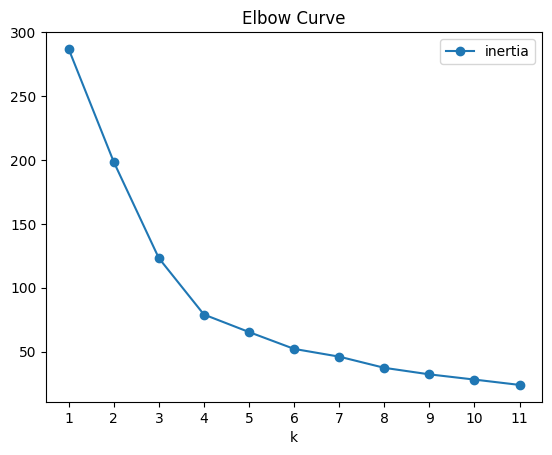

In [94]:
# Plot a line chart
elbow_plot = elbow_df.plot.line(
    x="k", 
    y="inertia", 
    title="Elbow Curve", 
    xticks=k_values,
    style='-o'
)

elbow_plot

### Checkpoint 3 — Choose k with Evidence

Choose best_k from your Elbow curve. State the bend or diminishing reduction that supports your choice, rather than simply reporting a number.

*Brief written answer: 1–2 sentences, using your own output.*

**Your brief answer:**

_Write 1–2 sentences and point to your result._

Based on the elbow curve, the inertia drops the steepest from k=1 to k=4 and then it leves afterward, showing that a diminished drop k=4. Therefore, the optimal value is best_k = 4

---

### Cluster Coins Using the Seven Scaled Features
Fit `k_model` using your chosen `best_k`, and store its labels in `clusters`.
Create `scaled_df` as a copy of `market_scale_df` with a `predicted_clusters`
column. Save the scatter chart as `market_scaled_plot`.

The model uses **all seven scaled features**. The scatter chart displays only
two of them. A cluster number is an identifier, not a rank or a known coin type.
Do not include an existing cluster-label column in a later model's input.

In [95]:
# Initialize the K-Means model using the best value for k
best_k = 4
k_model = KMeans(n_clusters=best_k, random_state=0, n_init=10)

# Fit the model to the scaled data
k_model.fit(market_scale_df)


KMeans(n_clusters=4, n_init=10, random_state=0)

In [96]:
# Predict the clusters to group the cryptocurrencies using the scaled DataFrame
clusters = k_model.predict(market_scale_df)

# Print the resulting array of cluster values.
print(clusters)


[2 2 0 0 2 2 2 2 2 0 0 0 0 2 0 2 0 0 2 0 0 2 0 0 0 0 0 0 2 0 0 0 1 2 0 0 3
 0 0 0 0]


In [97]:
# Create a copy of the scaled DataFrame
scaled_df = market_scale_df.copy()

In [98]:
# Add a new column to the copy of the scaled DataFrame with the predicted clusters
scaled_df['predicted_clusters'] = clusters

# Display the copy of the scaled DataFrame
scaled_df.head()


,price_change_percentage_24h,price_change_percentage_7d,price_change_percentage_14d,price_change_percentage_30d,price_change_percentage_60d,price_change_percentage_200d,price_change_percentage_1y,predicted_clusters
coin_id,,,,,,,,
bitcoin,0.508529,0.493193,0.772200,0.235460,-0.067495,-0.355953,-0.251637,2
ethereum,0.185446,0.934445,0.558692,-0.054341,-0.273483,-0.115759,-0.199352,2
tether,0.021774,-0.706337,-0.021680,-0.061030,0.008005,-0.550247,-0.282061,0
ripple,-0.040764,-0.810928,0.249458,-0.050388,-0.373164,-0.458259,-0.295546,0
bitcoin-cash,1.193036,2.000959,1.760610,0.545842,-0.291203,-0.499848,-0.270317,2


In [100]:
# Create a scatter plot
market_scaled_plot = scaled_df.hvplot.scatter(
    x="price_change_percentage_24h",
    y="price_change_percentage_7d",
    by="predicted_clusters",
    hover_cols=["coin_id"],
    title="Cryptocurrency Clusters (Scaled Features)"
)
market_scaled_plot

:NdOverlay   [predicted_clusters]
   :Scatter   [price_change_percentage_24h]   (price_change_percentage_7d,coin_id)

### Give the Clusters Meaning
Return to the **original percentage-change values**. Create `cluster_profile`
by attaching `clusters` to a copy of `df_market_data`. Show the number of coins
in each cluster and mean changes for two or three time windows of your choice.

Describe one contrast between two clusters using values from your table. If a
cluster has only one coin, mention that its mean describes that coin alone.
Suggest a descriptive name for one group, grounded in the observed data.

In [102]:
# Summarize cluster sizes and selected original-unit means.
cluster_profile = df_market_data.copy()
cluster_profile['predicted_clusters'] = clusters

# We will pick the features we are showcasing into a list
features_to_show = [
    'price_change_percentage_24h',
    'price_change_percentage_7d',
    'price_change_percentage_200d',
    'price_change_percentage_1y'
]

# Compute coin count along with the mean percentage changes per cluster
cluster_summary = cluster_profile.groupby('predicted_clusters')[features_to_show].agg(['count', 'mean'])
cluster_summary

price_change_percentage_24h             \
                                         count       mean   
predicted_clusters                                          
0                                           26  -0.182952   
1                                            1 -13.527860   
2                                           13   0.362635   
3                                            1   2.513230   

                   price_change_percentage_7d             \
                                        count       mean   
predicted_clusters                                         
0                                          26   0.907935   
1                                           1   4.212660   
2                                          13  11.996964   
3                                           1   0.603540   

                   price_change_percentage_200d               \
                                          count         mean   
predicted_clusters                                             
0                                            26   155.737093   
1                                             1  2227.927820   
2                                            13   140.826998   
3                                             1  1590.191490   

                   price_change_percentage_1y               
                                        count         mean  
predicted_clusters                                          
0                                          26   123.299271  
1                                           1  7852.089700  
2                                          13    91.291790  
3                                           1  2009.722170

### Checkpoint 4 — Interpret the Groups

Using the original-unit profile, describe one contrast between two clusters. Explain whether the scatter shows every feature used to create them.

*Brief written answer: 1–2 sentences, using your own output.*

**Your brief answer:**

_Write 1–2 sentences and point to your result._

---

### Reduce Seven Features to Three Principal Components
PCA builds new numerical coordinates from combinations of the scaled features.
It does not simply select three original columns. Its components are ordered
by the variance they capture. Reducing dimensions leaves some variance out;
it does not guarantee better clusters.

Fit a three-component PCA on `market_scale_df`, producing `pca_data`. Save
the individual explained-variance ratios as `explained_variance`. Create
`pca_df` with columns `PC1`, `PC2`, `PC3` and the original coin index.
No cluster-label column should enter PCA.

In [61]:
# Create a PCA model instance and set `n_components=3`.


In [62]:
# Perform PCA on the scaled data


# View the scaled PCA data


In [63]:
# Retrieve the explained variance ratio of each principal component


In [64]:
# Print the total variance explained


### Checkpoint 5 — What PCA Retains

Report the retained and omitted variance for the three components. Did PCA choose three original columns, and does the percentage prove better clusters?

*Self-check / group discussion: no separate written answer required.*

In [65]:
# Create a new DataFrame with the PCA data.


# Copy the crypto names from the original scaled DataFrame


# Set the coin_id column as index


# Display the scaled PCA DataFrame


---

### Choose k Again in the Three-Component PCA Space
Repeat the Elbow procedure using the three columns in `pca_df`. Create
`k_pca_values`, `inertia_pca`, `elbow_pca_df` and `elbow_pca_plot`.
Inspect the curve before choosing `best_k_pca`; it need not match `best_k`.
Read each curve within its own space. A lower inertia after projection is not,
by itself, proof of improved clustering: the coordinates and retained variance
have changed.

In [66]:
# Create a list with the number of k-values from 1 to 11


In [67]:
# Create an empty list to store the inertia values


# Loop through the k-values

    # Create the KMeans model
    
    
    # Fit the model to the data
  
    
    # Append the inertia to the inertia list


In [68]:
# Create a dictionary with the data to plot the Elbow curve


# Create a DataFrame with the data to plot the Elbow curve


In [69]:
# Plot the Elbow Curve


### Checkpoint 6 — Choose k after PCA

Choose best_k_pca from the second Elbow curve. Does it match best_k? Why is a lower inertia in this different coordinate space not enough to prove improvement?

*Self-check / group discussion: no separate written answer required.*

### Cluster Coins Using the Three PCA Components
Fit `k_pca_model` using `best_k_pca` on `pca_df`; save labels as `pca_clusters`.
Create `pca_market_df`, adding a `Predicted Clusters` column, and save a
PC1-versus-PC2 chart as `market_pca_plot`.

In [70]:
# Initialize the K-Means model using the best value for k

# Fit the K-Means model using the PCA data


In [71]:
# Predict the clusters to group the cryptocurrencies using the scaled PCA DataFrame

# Print the resulting array of cluster values.


In [72]:
# Create a copy of the scaled PCA DataFrame

# Add a new column to the copy of the PCA DataFrame with the predicted clusters

# Display the copy of the scaled PCA DataFrame


In [73]:
# Create a scatter plot using hvPlot


### Compare the Results Carefully
Display the two Elbow curves side by side. Then display the two cluster charts
side by side, each with its own axes: standardized changes and PCA coordinates
cannot be overlaid as if they were the same measurements.

Use the plots and your cluster profile for a brief comparison in the final
conclusion; no separate report is needed. The numeric label 0 in one run need
not identify the same group as label 0 in the other. If you want to check the
same coins more closely, the membership table below is an optional extension,
not another required analysis.

In [74]:
# Display elbow_plot and elbow_pca_plot side by side.
# In hvPlot, + creates separate panels.


In [75]:
# Display market_scaled_plot and market_pca_plot side by side.
# Keep the standardized-feature and PCA axes separate.


#### Optional: Follow the Same Coins

This table is for a closer check if useful. It is not required for completion.

In [76]:
# Optional: build membership and summarize the PCA clusters in original units.
# Compare which named coins remain together, not label numbers alone.


### Checkpoint 7 — Compare and Conclude

Give one supported observation comparing before and after PCA and one limitation. Reuse existing EDA or profile evidence; no separate report is needed.

*Brief written answer: 1–2 sentences, using your own output.*

**Your brief answer:**

_Write 1–2 sentences and point to your result._

Data for this dataset was generated by _edX Boot Camps LLC_, and is intended for educational purposes only.

## Closing Discussion — My Reasoning and the LLM's

Choose one finding or conclusion from **any part of this notebook**: data
exploration, scaling, clustering, PCA, or the comparison of representations.
Use an existing chart, table or model result; no new plot or report is needed.

1. **My thinking first:** State your observation and interpretation in 1–2 sentences,
   with a value or a specific feature of your output, before asking the model.
2. **The model's view:** Share that evidence and your interpretation. Ask:
   "Which parts of my interpretation are supported? Give an alternative explanation
   or limitation, in at most three sentences, without code."
3. **My evidence-based verdict:** Compare the replies. What agrees or differs?
   What do you accept or correct in your own claim, the model's claim, both or
   neither, and why? If the evidence is insufficient, say what remains uncertain.

Keep the tool/model name and relevant short reply. Two or three sentences for
your verdict are enough. Agreement needs evidence too; you do not have to find
a model error. One short exchange is enough; a follow-up is optional. Use this
as the closing discussion, not an additional essay. If no LLM is available,
compare your initial interpretation with a plausible alternative you write
yourself and label it the offline alternative.


**My initial interpretation and evidence:**

_Your own view first._

**Tool/model, question and relevant short reply:**

_Record the short exchange._

**What I now accept, correct or cannot decide — and why:**

_Compare both claims against your output._